# Cancellation classification: logistic regression baseline
Run `classification_feature.ipynb` first to prepare the CSVs. This notebook loads those splits and defines one pipeline containing imputation, scaling/encoding, and logistic regression.

**This notebook has not been run to train a model.** Run cells in order when ready. No files are saved by this notebook. All learned preprocessing is fitted only on training rows.

Prediction is immediately after booking creation. The same input-availability assumptions and general-EDA limitations still apply, including the target-dependent zero-guest filter. ADR remains excluded until its booking-time availability is settled.

In [ ]:
from pathlib import Path
import warnings
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
    recall_score, f1_score, balanced_accuracy_score, brier_score_loss, confusion_matrix, log_loss)

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/data/classification_features/basic/train.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run classification_feature.ipynb first, then open this notebook from within the repository')
DATA_DIR = ROOT / 'src/data/classification_features/basic'

## 1. Load original inputs and targets
Load Agent as a string: it is an identifier, not a numeric measurement. The source row ID is metadata and must not be used as a predictor. Reuse the existing chronological splits; do not split them again.

In [2]:
CATEGORICAL = ['Meal', 'Country', 'MarketSegment', 'DistributionChannel',
               'ReservedRoomType', 'DepositType', 'Agent', 'CustomerType', 'ArrivalDateMonth']
NUMERIC = ['LeadTime', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults',
           'Children', 'Babies', 'IsRepeatedGuest', 'PreviousCancellations',
           'PreviousBookingsNotCanceled', 'ArrivalDateYear', 'ArrivalDateDayOfMonth']
FEATURES = NUMERIC + CATEGORICAL

def load_split(name):
    frame = pd.read_csv(DATA_DIR / f'{name}.csv', dtype={col: object for col in CATEGORICAL})
    assert set(frame.columns) == set(FEATURES + ['source_row_id', 'IsCanceled'])
    assert frame.source_row_id.is_unique
    assert frame.IsCanceled.notna().all() and set(frame.IsCanceled.unique()) == {0, 1}
    return frame[FEATURES].copy(), frame.IsCanceled.astype(int), frame.source_row_id

X_train, y_train, train_ids = load_split('train')
X_valid, y_valid, valid_ids = load_split('validation')
assert set(train_ids).isdisjoint(valid_ids)
print('Training inputs:', X_train.shape, '| validation inputs:', X_valid.shape)
# Test data is loaded only in the optional final-evaluation cell.

Training inputs: (26375, 20) | validation inputs: (4157, 20)


## 2. Preprocessing inside the model pipeline
1. **Missing values:** median for numeric inputs and most-frequent category for categorical inputs. Current cleaned data has no missing cells, but the pipeline supports future missing inputs.
2. **Standardization:** `StandardScaler` subtracts the training mean and divides by training standard deviation. This is z-score scaling, not 0â€“1 min-max normalization. It makes scales comparable for logistic regression regularization and optimization; it does not make data normally distributed or remove outliers.
3. **One-hot encoding:** represent categories without imposing a false ordering. Categories occurring fewer than 20 times in training are grouped to limit sparse, unstable indicators. This cutoff is a starting choice. Unseen categories are supported.

Fit everything on training data only, then transform validation/test. Keep original numeric features; no ratios, sums, logs, cyclical features, feature selection, or resampling. The transformations run automatically when fitting or predicting with the pipeline.

In [3]:
preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), NUMERIC),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='infrequent_if_exist',
                                  min_frequency=20, sparse_output=True)),
    ]), CATEGORICAL),
], sparse_threshold=1.0)

model = Pipeline([
    ('preprocess', preprocessor),
    ('classifier', LogisticRegression(C=1.0, solver='lbfgs', max_iter=2000, random_state=42)),
])
# Defining the pipeline does not fit it.

## 3. Why start with logistic regression before XGBoost?
Logistic regression is a useful **first benchmark**, not a claim of higher accuracy.

| Consideration | Logistic regression | Tree-based XGBoost |
|---|---|---|
| First experiment | A compact baseline with regularization strength as the main tuning choice | More interacting choices: tree depth, learning rate, boosting rounds, subsampling and regularization |
| Understanding the model | Signed coefficients describe conditional log-odds associations; correlated features and encoding affect interpretation | Interactions across trees require additional interpretation tools |
| Relationship shape | Additive and linear in log-odds with these basic inputs; may underfit | Can capture nonlinear thresholds and feature interactions without manually constructing them |
| Scaling | Scaling helps optimization and comparable regularization | Tree splits generally do not require numeric scaling |
| Predictive performance | Must be measured | May outperform the linear baseline on this tabular dataset; must be measured |

For our current goal, logistic regression lets us first check whether eligible original inputs provide useful signal and establish a result we can explain. Then compare XGBoost on the same training/validation cohorts, tuning only on validation (or time-aware cross-validation). Neither model is protected from leakage or biased cleaning, and neither has guaranteed probability calibration.

Start with logistic regression; compare average precision, ROC-AUC, precision, recall, F1, and calibration. Choose thresholds from validation data using business costs. The earlier experiment already inspected the existing test cohort, so a genuinely fresh future holdout is needed for unbiased final assessment of later model choices. The following cells train and evaluate the first basic baseline when you run them.

References: [scikit-learn LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html).

## 4. Train and plot training loss
Preprocessing is fitted once on training rows. Warm-started L-BFGS checkpoints reuse coefficients but restart optimizer state, so this is a checkpoint history rather than an uninterrupted optimizer trace. Training log loss prints every 25 solver iterations and is plotted after training. Log loss excludes the regularization penalty. Stopping uses training convergence only. Rerunning this cell starts fresh.


Iteration 25: training log loss = 0.471259
Iteration 50: training log loss = 0.468692
Iteration 75: training log loss = 0.468271
Iteration 100: training log loss = 0.468086
Iteration 114: training log loss = 0.468059
Converged.
Final training log loss: 0.468059


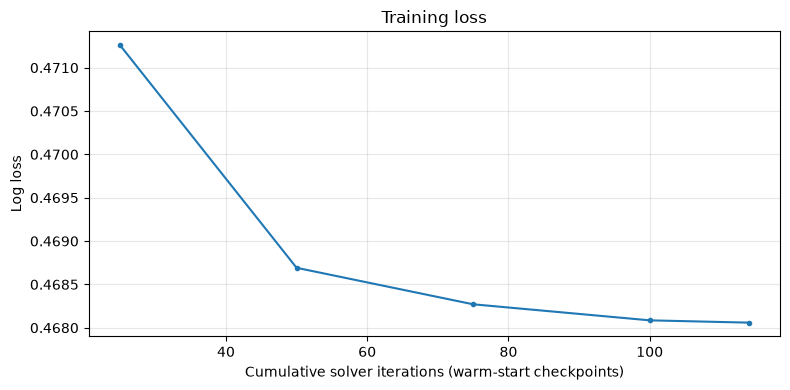

In [7]:
model = clone(model)
X_train_transformed = model.named_steps['preprocess'].fit_transform(X_train, y_train)
classifier = model.named_steps['classifier']
classifier.set_params(warm_start=True)
training_history = []
total_iterations = 0
converged = False
while total_iterations < 2000:
    classifier.set_params(max_iter=min(25, 2000 - total_iterations))
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        classifier.fit(X_train_transformed, y_train)
    convergence_messages = [w for w in caught if issubclass(w.category, ConvergenceWarning)]
    for warning in caught:
        if not issubclass(warning.category, ConvergenceWarning):
            warnings.warn(str(warning.message), warning.category)
    iterations = int(classifier.n_iter_.max())
    total_iterations += iterations
    probability = classifier.predict_proba(X_train_transformed)[:, 1]
    loss = log_loss(y_train, probability, labels=[0, 1])
    training_history.append({'iterations': total_iterations, 'log_loss': loss})
    print(f'Iteration {total_iterations}: training log loss = {loss:.6f}', flush=True)
    if not convergence_messages:
        converged = True
        break
    if iterations == 0:
        print('Solver made no progress:', str(convergence_messages[-1].message))
        break
training_history = pd.DataFrame(training_history)
print('Converged.' if converged else 'Stopped without confirmed convergence; inspect before interpreting results.')
print(f'Final training log loss: {loss:.6f}')
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(training_history.iterations, training_history.log_loss, marker='o', markersize=3)
ax.set(title='Training loss', ylabel='Log loss',
       xlabel='Cumulative solver iterations (warm-start checkpoints)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
# Fitted preprocessing and classifier remain inside model for validation predictions.

## 5. Compare training and validation performance
The table shows accuracy, error rate (1 - accuracy), log loss, and the existing classification metrics for both datasets. Accuracy and error rate are fractions: 0.80 means 80%. Lower error rate and log loss are better. Predictions use threshold 0.50. Balanced accuracy is a separate metric averaging recall across classes. Tune decisions on validation only; test data is not used here.


In [8]:
def score_predictions(actual, probability, threshold=0.5):
    predicted = probability >= threshold
    return {
        'Accuracy': float(np.mean(np.asarray(actual) == predicted)),
        'ErrorRate': float(np.mean(np.asarray(actual) != predicted)),
        'LogLoss': log_loss(actual, probability, labels=[0, 1]),
        'ROC_AUC': roc_auc_score(actual, probability),
        'AveragePrecision': average_precision_score(actual, probability),
        'Precision': precision_score(actual, predicted, zero_division=0),
        'Recall': recall_score(actual, predicted, zero_division=0),
        'F1': f1_score(actual, predicted, zero_division=0),
        'BalancedAccuracy': balanced_accuracy_score(actual, predicted),
        'Brier': brier_score_loss(actual, probability),
    }

THRESHOLD = 0.50
train_probability = model.predict_proba(X_train)[:, 1]
valid_probability = model.predict_proba(X_valid)[:, 1]
display(pd.DataFrame({
    'Training': score_predictions(y_train, train_probability, THRESHOLD),
    'Validation': score_predictions(y_valid, valid_probability, THRESHOLD),
}).T.round(4))
display(pd.DataFrame(confusion_matrix(y_valid, valid_probability >= THRESHOLD, labels=[0,1]),
    index=['Actual not canceled', 'Actual canceled'],
    columns=['Predicted not canceled', 'Predicted canceled']))

,Accuracy,ErrorRate,LogLoss,ROC_AUC,AveragePrecision,Precision,Recall,F1,BalancedAccuracy,Brier
Training,0.7637,0.2363,0.4681,0.7934,0.5666,0.6098,0.2911,0.3941,0.6121,0.1535
Validation,0.7546,0.2454,0.5011,0.7465,0.4944,0.5580,0.1684,0.2587,0.5615,0.1628


,Predicted not canceled,Predicted canceled
Actual not canceled,2959,141
Actual canceled,879,178


## 6. Optional test evaluation after model decisions are fixed
Keep the switch off during development. After settling inputs, hyperparameters, and threshold using validation, enable it for a final assessment.

The historical test cohort was already inspected in an earlier experiment. It can still provide a descriptive comparison, but a new future holdout is required for a genuinely fresh final evaluation. Test results must not guide further tuning.

In [10]:
RUN_TEST_EVALUATION = 1
if RUN_TEST_EVALUATION:
    X_test, y_test, test_ids = load_split('test')
    assert set(test_ids).isdisjoint(train_ids) and set(test_ids).isdisjoint(valid_ids)
    test_probability = model.predict_proba(X_test)[:, 1]
    display(pd.DataFrame([score_predictions(y_test, test_probability, THRESHOLD)],
                         index=['Logistic regression test']).round(4))
else:
    print('Test evaluation skipped. Finish validation decisions first.')

,Accuracy,ErrorRate,LogLoss,ROC_AUC,AveragePrecision,Precision,Recall,F1,BalancedAccuracy,Brier
Logistic regression test,0.7137,0.2863,0.5261,0.74,0.5041,0.5254,0.2525,0.3411,0.5789,0.1781
